# Lesson 16: Chronoamperometry: Fick's Laws, the Cottrell Equation and Ultramicroelectrodes
With thermodynamics, kinetics, mass transfer and ionic balance introduced, we now have a basic understanding of the core phenomena underlying electrochemistry. Moving forwards we will introduce experimental techniques and use them to refine that understanding. We start with the simplest perturbation available: step the potential and watch.

Today's topics:
- First experimental technique: Chronoamperometry
- Fick's laws, diffusion geometry and boundary conditions
- The Cottrell equation and the growing diffusion layer
- Radial diffusion, ultramicroelectrodes and steady state currents

**Reference:**
- Sections 5.1 to 5.3 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE      # constants and the two-panel figure size
from echem import erf                   # vectorised: hand it a whole array at once
echem.use_style()                       # course-wide graph formatting

# 1. Waveforms

Electrochemical experiments involve the application of some perturbation to the surface of an electrode, which is paired with monitoring of potential and or current. The perturbation generally involves application of either a potential or a current and paired monitoring of the other. The perturbation is typically discussed in terms of a **waveform**: the applied perturbation as a function of *time*. Waveforms are represented using a series of parameters, with unique parameters defined for each type of experiment.

We will start today with the most basic experiment: a **potential step**. The waveform for a potential step is simple a step from one voltage to another:

Text(0.5, 0.5, '?')

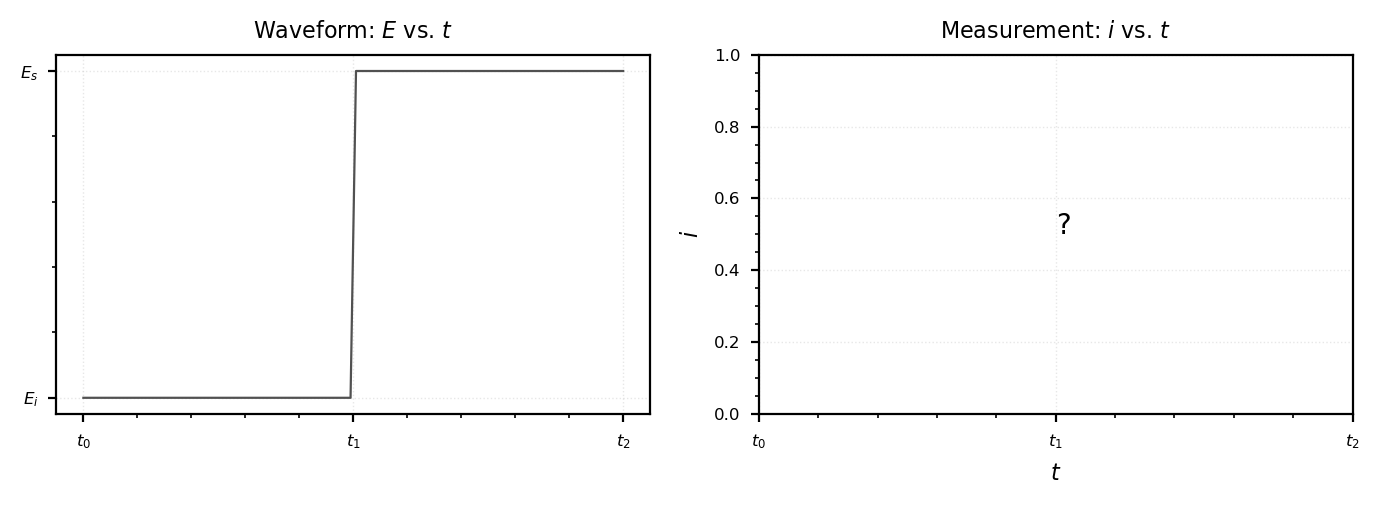

In [2]:
# The simplest perturbation there is: step the potential and watch the current.
t, e = echem.step_waveform(e_initial=0.0, e_step=1.0, t_total=1.0)

fig = plt.figure(figsize=WIDE)
ax1 = plt.subplot(121)
ax2 = plt.subplot(122)

for ax in [ax1, ax2]:
    ax.set_xticks([0, 0.5, 1.0])
    ax.set_xticklabels([r"$t_0$", r"$t_1$", r"$t_2$"])

ax1.set_title(r'Waveform: $E$ vs. $t$')
ax1.set_yticks([0, 1.0])
ax1.set_yticklabels([r"$E_i$", r"$E_s$"])
ax1.plot(t, e)

ax2.set_title(r'Measurement: $i$ vs. $t$')
ax2.set_xlabel(r'$t$')
ax2.set_ylabel(r'$i$')
ax2.annotate('?', (0.5, 0.5))

#### Potential Step Waveform:

The specific variables representing the parameters will vary from instrument to instrument, but the parameters are:
- $\large E_i$: Initial potential. A voltage that is typically chosen to be $E_{OC}$, or some other voltage where no Faradaic charge is passed. 
- $\large E_s$: Step potential. The voltage that is applied to the electrode.
- $\large t_q$: Quiet time. Period at which the system is left to rest before experiment. $t_1 - t_0$ in the above figure.
- $\large t$: Time. Time that the potential step is applied. $t_2 - t_1$ in the above figure.

<div class="alert alert-block alert-info">
<b>Activity:</b> The above figure shows the simplest perturbation: a step from a large cathodic overpotential to a large anodic overpotential. Grab a pen. Sketch out the behavior you expect to measure, assuming that the reduced species is present at 1 mM concentration in bulk solution, with no oxidized species.
</div>

As usual, we begin by considering our generic reaction:

$ \large O + e^- \rightleftharpoons R$

Only $R$ is present in bulk solution, we can define:

$ \large C_R^* = C_R(x=0,t=0) = 1 mM $

Where to from here? It depends on the situation.

#### General description

We previously developed the **Butler-Volmer equation**, which relates current to overpotential. Here, we will simplify it by defining:

$\large f = \frac{F}{RT}$

Such that:

$
\large i = F A k^0 \left[ C_R(0,t)e^{(1-\alpha) f (E-E^{0'}) } -  C_O(0,t)e^{-\alpha f (E-E^{0'})} \right]
$

This equation dictates the behavior we seek...but it contains variables that we don't know! The variables we work with are $E$, $i$, and $t$. However, $t$ is indirectly present in the form of $C_i(0, t)$. In order to solve the full equation we need to develop a means to determine the magnitude of the $C_i(0,t)$ terms. These terms, as we previously learned, are dependent on mass transport.

<div class="alert alert-block alert-danger">
<b>Memory Check:</b> What are the three modes of mass transport relevant to our measurements?
</div>

#### Limiting Conditions

Much of experimental electrochemistry involves attempting to force a system into **limiting conditions**, where the observed behavior is simplified. We have already seen this in several situations.

#### Kinetically Limited Currents

Measured currents can be completely dictated by electron transfer kinetics. Such kinetically limited conditions may exist when we apply very small potential steps such that diffusion layers are negligible:

$\large i = i_0f\eta$

Or they can occur at larger overpotentials if we can remove mass transport considerations, such as by stirring the solution vigorously:

$\large ln(i) = ln(i_0) - \alpha f\eta$

#### Diffusion Limited Currents

If kinetics are not an issue, perturbations to the system often yield diffusion limited conditions. Currents may be then, for example:

$\large |i_{lim,c}| = nFAm_OC_O^*$

This situation appears very often during experiments, but we must remember that the $m_i$ terms are often time-dependent themselves:

$\large m_O = \frac{D_O}{\delta_O}$

We are therefore in the situation where we can only solve one limiting condition (kinetics) without knowing anything about $C_i(0,t)$. Luckily, we can refine our understanding of **diffusion layers** to establish dependable mathematical models that can be applied (with extreme caution!).

# 2. Fick's Laws of Diffusion

The movement of matter by diffusion is governed by **Fick's Laws**. We have already seen **Fick's first law** in [Lesson 14](L14-Mass-Transfer-Limitations.ipynb):

$\large J_i = -D_j \frac{\delta C_j(x,t)}{\delta x}$

This law states that matter will move from a region of high concentration to low concentration with a rate that is proportional to the concentration gradient.

**Fick's second law** defines the concentration gradient as a function of time:

$\large \frac{\delta C_j}{\delta t} = D_j \triangledown^2 C_j$

This equation brings in a new term that is likely new to many: the **Laplace operator** ($\triangledown^2$).

Fick's second law is a **partial differential equation**. Concentration (a variable) is dependent on time (a second variable) and distance from the electrode (a third variable). The law defines the change in concentration with time, necessitating that distance is factored in somewhere. The Laplace operator is a differential operator that (here) represents our distance variable.

#### Distance from Electrode

So far we have referred to distance as simply "distance from the electrode." With a little thought it is not hard to see that this is a vague definition. The shape of the electrode is critically important. The shape of the electrode dictates the **geometry for diffusion**.

The Laplace operator that one uses is entirely dependent on the geometry of diffusion. The table below provides common electrode geometries, variables necessary to describe distance, and the appropriate Laplace Operator.

|Diffusion Geometry|Variables| $\large \triangledown^2$|Example|
|---|---|---|---|
|Linear|x|$\large \frac{\delta^2}{\delta x^2}$|macrodisk electrode|
|Spherical| r| $\large \frac{\delta^2}{\delta r^2} + \frac{2}{r}\frac{\delta}{\delta r}$| hanging mercury droplet|
|Cylindrical| r | $\large \frac{\delta^2}{\delta r^2} + \frac{1}{r}\frac{\delta}{\delta r}$| wire electrode|
|Disk| r, z | $\large \frac{\delta^2}{\delta r^2} + \frac{1}{r}\frac{\delta}{\delta r} + \frac{\delta^2}{\delta z^2}$| ultramicroelectrode|
|Band| x, z | $\large \frac{\delta^2}{\delta x^2} + \frac{\delta^2}{\delta z^2}$| band electrodes|

<div class="alert alert-block alert-info">
<b>Activity:</b> Sketch the diffusion geometries. Remember that this geometry describes how the solvated species moves, not the geometry of the electrode.
</div>

# 3. Macrodisk Electrodes
#### Establishing a Model

Partial differential equations can only be solved when boundary conditions are defined. To solve the equation we must:
1.  select the diffusion geometry that represents the electrode
2. **make some assumptions** about how the diffusion layer will act

We will consider this behavior as a *model* because it relies upon the validity of the assumptions that are made. We will start by building up the equations for the simplest example: linear diffusion towards a macrodisk electrode. This will be explored for the following system:

$\large O + e^- \rightleftharpoons R$

$\large C_O^*/C_T = 1.0 $

$\large C_R^*/C_T = 0 $

With the following perturbation applied: 

$\large E_i >> E^0$

$\large E_s << E^0$

A **macrodisk** electrode is one which has the appropriate geometry to ensure only **linear diffusion**. This is often a circular disk, such as the end of a polished rod, that is inserted into an insulating body, which is often polyethylene, Teflon, or some other chemically resistant plastic. The **radius** ($r_0$) of the disk needs to be sufficiently large so as to ensure only linear diffusion. Traditionally, this is considered to be $r_0 > 25 \mu m$. The system looks like this:

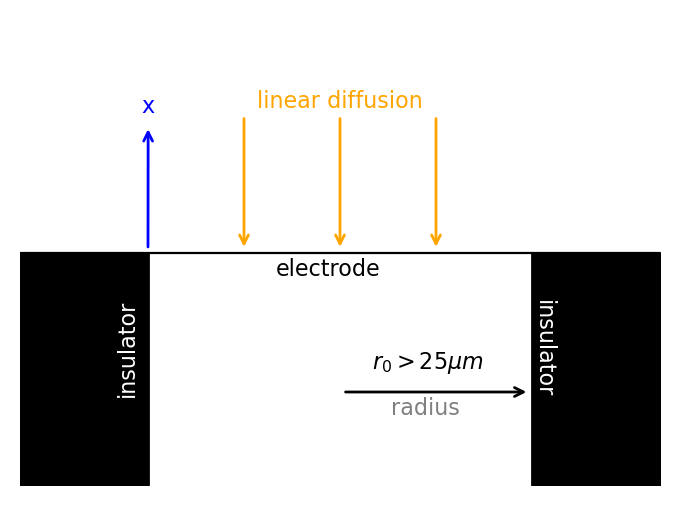

In [3]:
fig = plt.figure()
ax = plt.subplot()
ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.set_axis_off()

ax.plot([0, 1], [0.5, 0.5], 'black')
ax.annotate('electrode', (0.4, 0.45), fontsize=8)
ax.fill_between([0, 0.2], 0, 0.5, color='black')
ax.fill_between([0.8, 1.], 0, 0.5, color='black')
ax.annotate('insulator', (0.15, 0.2), rotation=90, color='white', fontsize=8)
ax.annotate('insulator', (0.8, 0.2), rotation=270, color='white', fontsize=8)

ax.annotate('radius', (0.58, 0.15), color='gray', fontsize=8)
ax.annotate(r'$r_0 > 25 \mu m$', (0.55, 0.25), fontsize=8)
ax.annotate('', fontsize=8,
            xy=(0.5, 0.2), xycoords='data', 
            xytext=(0.8, 0.2), textcoords='data', 
            arrowprops=dict(arrowstyle='<-', color='black')
           )

ax.annotate('x', fontsize=8, color='blue',
            xy=(0.2, 0.5), xycoords='data', 
            xytext=(0.19, 0.8), textcoords='data', 
            arrowprops=dict(arrowstyle='<-', color='blue')
           )

ax.annotate('linear diffusion', (0.37,0.81), color='orange', fontsize=8)
for x in [0.35, 0.5, 0.65]:
    ax.annotate('', fontsize=8,
                xy=(x, 0.5), xycoords='data', 
                xytext=(x, 0.8), textcoords='data', 
                arrowprops=dict(arrowstyle='->', color='orange')
               )

fig.savefig('../Workspace/lineardiffusion.png')

#### Establishing Boundary Conditions

The strategy for solving the equation is to establish equations necessary to describe the initial condition of the reaction system, then additional equations describing the limits (*boundaries*) to the time and distance dependent changes due to the applied perturbation. For the case at hand, we are considering 1-D diffusion.

We start by selecting the **Laplace operator** that corresponds to our diffusion geometry. The appropriate operator is substituted in for the $\triangledown^2$ term in **Fick's second law**:

$\large \frac{\delta C_j(x,t)}{\delta t} = D_j \frac{\delta^2 C_j(x,t)}{\delta x^2}$

We do know the initial concentration of species in solution, which tells us the initial equilibrium in solution and at the electrode surface:

$\large C_O(x,0) = C_O^*$

We then need to define the **boundary conditions** for the model: the equations that describe $C_j(x,t)$ at the limits of the model being developed. The first limit is at $x = 0$, which is the electrode surface. This equation is set by the perturbation, which we defined as a step from a large anodic $\eta$ to a large cathodic $\eta$. The equation is therefore:

$\large C_O(0,t) = 0$   for $\large t > 0 s$

A second boundary in this 1-D system is the furthest distance that the species can diffuse to. We will make the **semi-infinite diffusion** approximation here:

$\large \lim_{x \to \infty} C_O(x,t) = C_O^*$

<div class="alert alert-block alert-success">
<b>Semi-infinite solution approximation:</b> A solvated species can diffuse for an infinite distance; there is no limit to the size which the diffusion layer can grow. 
</div>

The boundary conditions enable a **Laplace transform** to be applied to Fick's laws. The actual execution of the transform is beyond the scope for this course, but the end result for *semi-infinite diffusion at a macrodisk electrode* is:

$\large i_d(t) = \frac{nFAD_O^{1/2}C_O^*}{\pi^{1/2}t^{1/2}}$

This equation is named the **Cottrell Equation**. It tells us that we should expect $i$ to decay with $\frac{1}{\sqrt{t}}$. Remember: this ONLY applies to a diffusion limited regime (hence the subscript *d*). Using the Cottrell equation, we can now finish the initial figure:

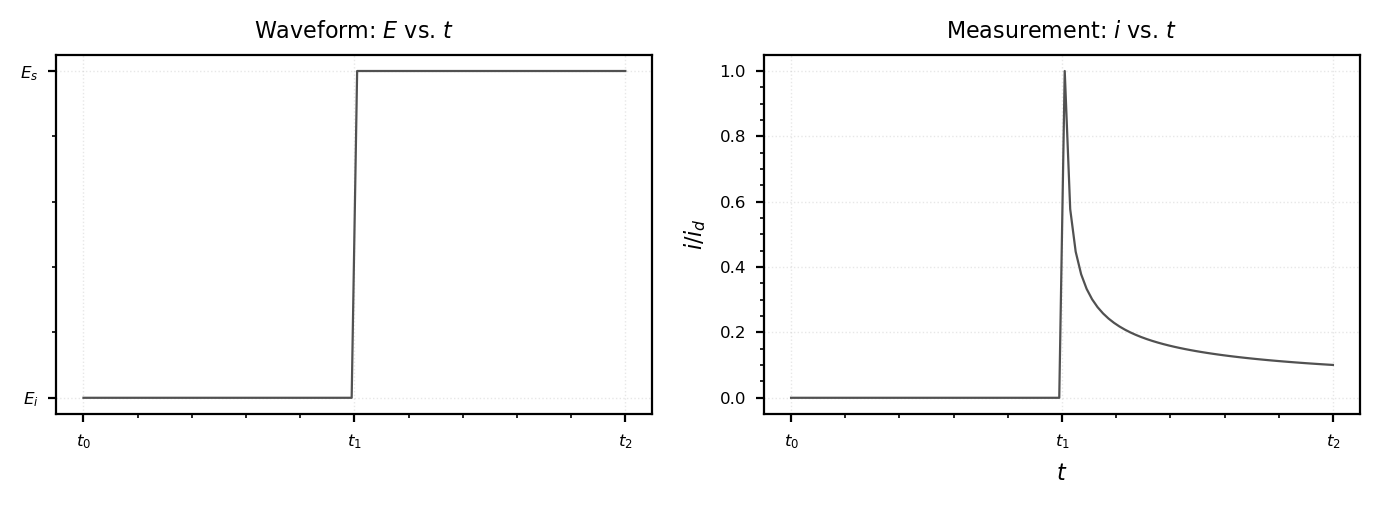

In [4]:
# The answer: the Cottrell decay.  Current is largest the instant the step is
# applied, then falls as the diffusion layer grows.
t, e = echem.step_waveform(e_initial=0.0, e_step=1.0, t_total=1.0)
t_after_step = t[t >= 0.5] - 0.5                    # time measured FROM the step
current = np.zeros(t.size)
current[t >= 0.5] = echem.cottrell(np.maximum(t_after_step, 1e-6), conc=1e-6)

fig = plt.figure(figsize=WIDE)
ax1 = plt.subplot(121)
ax2 = plt.subplot(122)

ax1.set_title(r'Waveform: $E$ vs. $t$')
ax1.set_xticks([0, 0.5, 1.0])
ax1.set_xticklabels([r"$t_0$", r"$t_1$", r"$t_2$"])
ax1.set_yticks([0, 1.0])
ax1.set_yticklabels([r"$E_i$", r"$E_s$"])
ax1.plot(t, e)

ax2.set_title(r'Measurement: $i$ vs. $t$')
ax2.set_xticks([0, 0.5, 1.0])
ax2.set_xticklabels([r"$t_0$", r"$t_1$", r"$t_2$"])
ax2.set_xlabel(r'$t$')
ax2.set_ylabel(r'$i / i_d$')
ax2.plot(t, current/current.max())

fig.savefig('../Workspace/potentialstep.png')

Look back at the diffusion limited current equation once more:

$\large |i_{lim,c}| = nFAm_OC_O^*$

If we compare this to the Cottrell equation:

$\large i_d(t) = \frac{nFAD_O^{1/2}C_O^*}{\pi^{1/2}t^{1/2}}$

We can see that the diffusion term has become formally defined:

$\large m_O = \frac{D_O}{\delta_O} =  \sqrt{\frac{D_O}{\pi t}}$ 

The lesson is: general diffusion-limited currents can be explicitly defined **IF** valid assumptions are made.

This predictability comes in very handy, allowing the theoretical calculation of currents and diffusion layers. The concentration profile can be quantified from these equations following another **Laplace transform**. We will not perform the transform here, but the result for the diffusion limited system is:

$\large C_O(x,t) = C_O^* erf\left[\frac{x}{2\sqrt{D_O t}} \right]$

Where $erf$ is the *error function*:

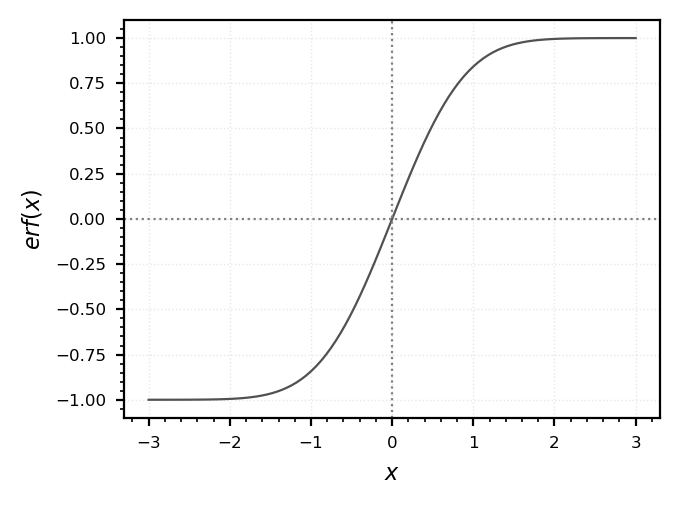

In [5]:
# The error function.  echem imports the vectorised version from scipy, so it
# takes the whole array at once: no Python loop needed.
x = np.linspace(-3, 3, 100)

fig = plt.figure()
ax = plt.subplot()
ax.plot(x, erf(x))
ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$erf(x)$')
ax.axhline(0, linestyle=':', color='gray')
ax.axvline(0, linestyle=':', color='gray')

Using this equation, we can calculate the concentration profile for any combination of $D_j$ and $t$.

Additionally, we can begin to describe the thickness of the diffusion layer using some multiple of $\sqrt{D_O t}$. 

In [6]:
@interact(d1=widgets.FloatText(value=0.00001, step=0.00001, description=r'$D_O^a (cm^2s^{-1})$'),
          t1=widgets.FloatText(value=0.001, step=0.0001, description=r'$t^a (s)$'),
          d2=widgets.FloatText(value=0.00001, step=0.00001, description=r'$D_O^b (cm^2s^{-1})$'),
          t2=widgets.FloatText(value=0.01, step=0.0001, description=r'$t^b (s)$'))
def plot_diffusion_profiles(d1, t1, d2, t2):
    '''Two concentration profiles, and the 2/4/6 sqrt(Dt) rules of thumb.'''
    if min(d1, t1, d2, t2) <= 0:
        print('D and t must all be greater than zero.')
        return
    fig = plt.figure()
    ax = plt.subplot()
    x = np.linspace(0., 0.006, 100)

    for (d, t, colour, tag) in [(d1, t1, 'black', 'a'), (d2, t2, 'red', 'b')]:
        ax.plot(x, echem.diffusion_profile(x, d, t), color=colour,
                label=fr'$D_O^{tag}$ = {d}, $t^{tag}$ = {t}')
        for multiplier in [2, 4, 6]:
            ax.axvline(echem.diffusion_layer_thickness(d, t, multiplier),
                       linestyle=':', linewidth=0.5, color=colour)

    ax.set_xlabel(r'$x$ /cm')
    ax.set_xlim(0, 0.003)
    ax.set_ylabel(r'$C_O/C_O^*$')
    ax.legend(fontsize=6, loc=4)

interactive(children=(FloatText(value=1e-05, description='$D_O^a (cm^2s^{-1})$', step=1e-05), FloatText(value=…

The vertical lines drawn on the diagram represent the 2, 4 and 6 times multipliers of the $\sqrt{D_O t}$ term. The efficacy of these multipliers can be demonstrated by comparison of the total area of perturbation:

| if x= | Perturbation captured (%) |
| --- | --- |
| 2 $\sqrt{D_O t}$  | 84.3 | 
| 4 $\sqrt{D_O t}$  | 99.5 |
| 6 $\sqrt{D_O t}$  | 99.998 |

More information is available on Page 165 in your Bard & Faulkner textbook.

# 4. Ultramicrodisk Electrodes

An **ultramicroelectrode** is one in which **radial diffusion** contributes to overall diffusion. This occurs when the size of the electrode shrinks. Let us consider the same initial conditions and perturbation, but using an ultramicroelectrode.

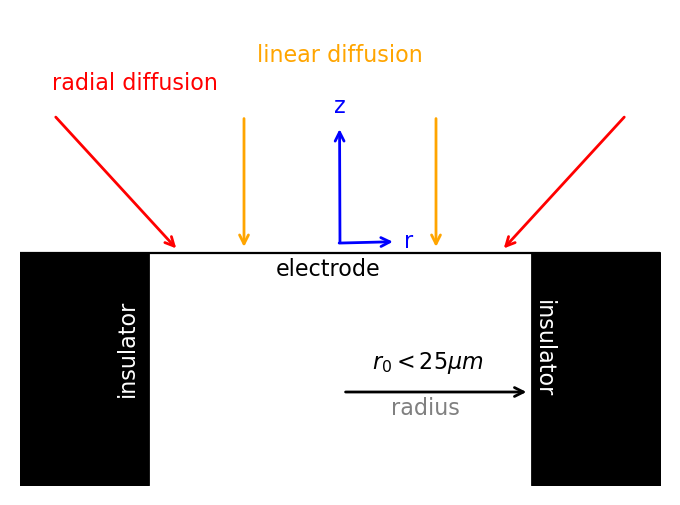

In [7]:
fig = plt.figure()
ax = plt.subplot()
ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.set_axis_off()

ax.plot([0, 1], [0.5, 0.5], 'black')
ax.annotate('electrode', (0.4, 0.45), fontsize=8)
ax.fill_between([0, 0.2], 0, 0.5, color='black')
ax.fill_between([0.8, 1.], 0, 0.5, color='black')
ax.annotate('insulator', (0.15, 0.2), rotation=90, color='white', fontsize=8)
ax.annotate('insulator', (0.8, 0.2), rotation=270, color='white', fontsize=8)

ax.annotate('radius', (0.58, 0.15), color='gray', fontsize=8)
ax.annotate(r'$r_0 < 25 \mu m$', (0.55, 0.25), fontsize=8)
ax.annotate('', fontsize=8,
            xy=(0.5, 0.2), xycoords='data', 
            xytext=(0.8, 0.2), textcoords='data', 
            arrowprops=dict(arrowstyle='<-', color='black')
           )

ax.annotate('z', fontsize=8, color='blue',
            xy=(0.5, 0.51), xycoords='data', 
            xytext=(0.49, 0.8), textcoords='data', 
            arrowprops=dict(arrowstyle='<-', color='blue')
           )

ax.annotate('r', fontsize=8, color='blue',
            xy=(0.49, 0.52), xycoords='data', 
            xytext=(0.6, 0.51), textcoords='data', 
            arrowprops=dict(arrowstyle='<-', color='blue')
           )

ax.annotate('linear diffusion', (0.37,0.91), color='orange', fontsize=8)
for x in [0.35, 0.65]:
    ax.annotate('', fontsize=8,
                xy=(x, 0.5), xycoords='data', 
                xytext=(x, 0.8), textcoords='data', 
                arrowprops=dict(arrowstyle='->', color='orange')
               )
    
ax.annotate('radial diffusion', (0.05, 0.85), color='red', fontsize=8)
ax.annotate('', fontsize=8,
            xy=(0.25, 0.5), xycoords='data', 
            xytext=(0.05, 0.8), textcoords='data', 
            arrowprops=dict(arrowstyle='->', color='red')
           )    
ax.annotate('', fontsize=8,
            xy=(0.75, 0.5), xycoords='data', 
            xytext=(0.95, 0.8), textcoords='data', 
            arrowprops=dict(arrowstyle='->', color='red')
           )    

fig.savefig('../Workspace/umediffusion.png')

#### Establishing Boundary Conditions

The distinguishing characteristic here is that species can now diffuse in from the side. This can be expected to increase the overall flux of the species to the electrode compared to a macrodisk.

The **Laplace operator** for this diffusion geometry requires both $z$ and $r$:

$\large \frac{\delta C_j(r, z, t)}{\delta t} = D_j \left[ \frac{\delta^2C_O(r,z,t)}{\delta r^2} + \frac{1}{r}\frac{\delta C_O(r,z,t)}{\delta r} + \frac{\delta^2C_O(r,z,t)}{\delta z^2}\right]
$

The initial concentration of species in solution remains the same, though we define it slightly differently:

$\large C_0(r, z, 0) = C_O^*$

The concept behind the **boundary conditions** remain the same here, but the addition of new variables means that we need more equations to solve the partial differential equation.

We will maintain the **semi-infinite diffusion** approximation here, but it needs to be defined for both distance variables:

$\large \lim_{r \to \infty} C_O(r,z,t) = C_O^*$

$\large \lim_{z \to \infty} C_O(r,z,t) = C_O^*$

Similarly, we define equations for the electrode surface, which is still a step from a large anodic $\eta$ to a large cathodic $\eta$, but need two versions:

$\large C_O(r,0,t) = 0$    for $\large r \leq r_0$ and $\large t > 0 s$

$\large \frac{\delta C_O(r, z,t)}{\delta z}|_{z=0} = 0$   for $\large r > r_0$

The first condition at the electrode surface is an updated version of our previous one. The second equation states that the change in concentration at the surface is zero for $r > r_0$, which is true because the surface is insulating.

With the boundary conditions set, a Laplace transform can once again be performed. The outcome is best summarized as a series of three equations. The first equation is that for the current:

$\large i = \frac{4nFAD_OC_O^*}{\pi r_0}f(\tau)$

The second equation is a **dimensionless time** parameter describing *characteristic* diffusion in a system:

$\large \tau = 4 \frac{D_Ot}{r_0^2}$

The final equation links the first two together:

$\large f(\tau) = 0.7854 + \frac{0.8862}{\sqrt{\tau}} + 0.2146e^{-\frac{0.7823}{\sqrt{\tau}}}  $

Inspection of the terms in the final equation shows the behavior that should be expected:
- The first is a constant. We can therefore expect that the current will **not** decay to zero, but to a non-zero **steady state limit**.
- The second term has an inverse time component. It will drop to zero as $t$ approaches infinity.
- The third term lists time as an inverse exponential. As $t$ approaches infinity, this term will go to 1.0. It is multiplied by a fraction that sums to 1.0 with the first term.

At long times, the equation will therefore simplify to a **steady state current** ($i_{ss}$):

$\large i_{ss} = 4nFD_OC_O^*r_0$

(remember that $A = \pi r^2$)

The **diffusion controlled currents** at **ultramicroelectrodes** can be broken into three distinct regions:
 - REMEMBER: slow electron transfer kinetics will alter this.

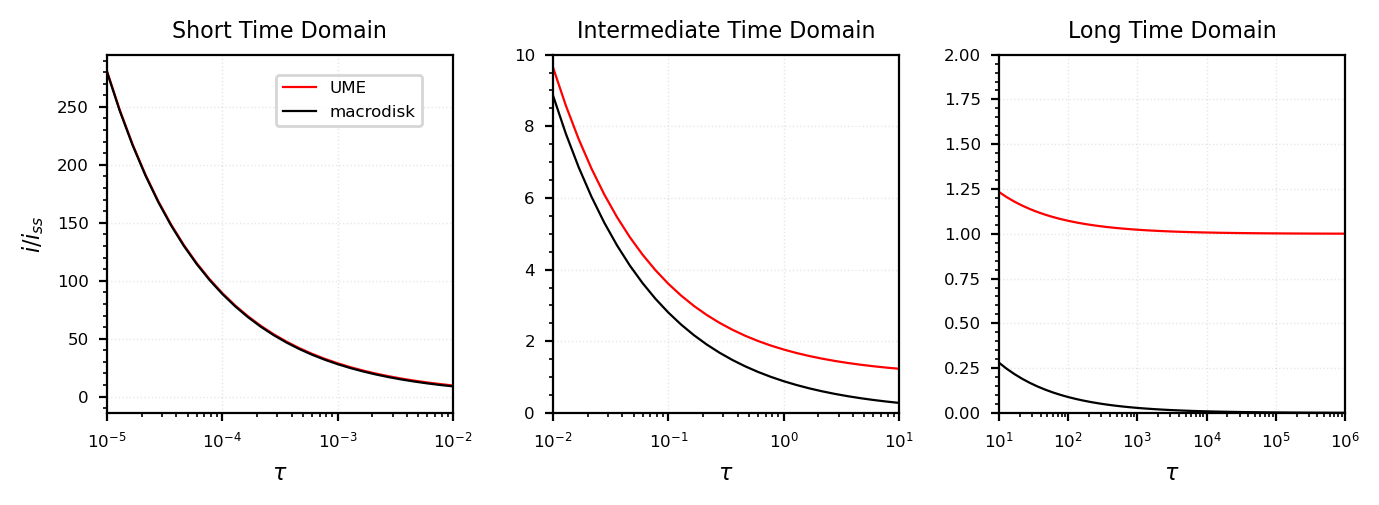

In [8]:
# Macrodisk and ultramicroelectrode compared on one dimensionless time axis.
# tau = 4 D t / r0^2, and both currents are normalised by the UME steady state
# current i_ss = 4 n F D C* r0.
tau = np.power(10, np.linspace(-5, 6, 100))
i_ume = echem.ume_current_function(tau)             # tends to 1 at long times
i_macrodisk = echem.macrodisk_current_function(tau)  # sqrt(pi)/(2 sqrt(tau))

fig, ax = plt.subplots(1, 3, figsize=WIDE)
ax[0].set_ylabel(r'$i/i_{ss}$')

for a in ax:
    a.set_xlabel(r'$\tau$')
    a.plot(tau, i_ume, 'red')
    a.plot(tau, i_macrodisk, 'black')
    a.set_xscale('log')

ax[0].set_xlim(1e-5, 1e-2)
ax[0].set_title('Short Time Domain')
ax[1].set_xlim(1e-2, 10)
ax[1].set_ylim(0, 10)
ax[1].set_title('Intermediate Time Domain')
ax[2].set_xlim(10, 1e6)
ax[2].set_ylim(0, 2)
ax[2].set_title('Long Time Domain')

fig.legend(labels=['UME', 'macrodisk'], fontsize=6, loc=(0.2, 0.75))
fig.savefig('../Workspace/comparison.png')

<div class="alert alert-block alert-info">
    <b>Activity:</b> Calculate the <b>time window</b> and <b>diffusion layer thickness</b> for each of these time domains exists. Assume typical values of $r_0$ (5 micron) and $D_j$ (1x10$^{-5}$ cm$^2$/s).
</div>

In [9]:
# Use this as workspace for the activity

The end result is that:
- The **short time domain** exists when $\delta_j << r_0$
- The **intermediate time domain** exists when $\delta_j \approx r_0$
- The **long time domain** exists when $\delta_j >> r_0$


<div class="alert alert-block alert-info">
    <b>Activity:</b> Consider the final panel in the image below. This image depicts a situation where the <b>semi-infinite diffusion</b> approximation has been violated for a UME electrode. The above math will no longer hold! How would you set about calculating $i(t)$?
</div>

<img src='../Resources/images/ume-diffusion.png'>